# Lab 2.3 - Quantization: Post-Training vs Quantization-Aware Training

This notebook has `# TODO` markers (TODO 1-6). Work through them in order.

Copy your `mnist_cnn.pth` from Lab 2.2 into this same folder before you start.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision import datasets
import litert_torch
import ai_edge_litert.interpreter as tflite
import ai_edge_quantizer as aeq
import matplotlib.pyplot as plt

torch.manual_seed(10)
np.random.seed(10)

print("PyTorch version:", torch.__version__)


I0000 00:00:1791810510.353129   50359 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
Failed to load /home/pukynd/TalTech/ias0360-lab-excercises-2026/.venv/lib/python3.14/site-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /home/pukynd/TalTech/ias0360-lab-excercises-2026/.venv/lib/python3.14/site-packages/torchao/_C_cutlass_90a.abi3.so
Failed to load /home/pukynd/TalTech/ias0360-lab-excercises-2026/.venv/lib/python3.14/site-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /home/pukynd/TalTech/ias0360-lab-excercises-2026/.venv/lib/python3.14/site-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so
W1012 16:08:30.821000 50359 .venv/lib/python3.14/site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subcl

PyTorch version: 2.14.1+xpu


## Step 0 - Load data and the Lab 2.2 model

Same MNIST preprocessing as Lab 2.2 (normalize to [0,1], add channel dim in NCHW format).
This part is provided for you.

Note: loaded with `torch.load("mnist_cnn.pth")` matching the model built in Lab 2.2.

In [2]:
train_dataset = datasets.MNIST(root="./data", train=True, download=True)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True)
x_train = train_dataset.data.numpy()
y_train = train_dataset.targets.numpy()
x_test  = test_dataset.data.numpy()
y_test  = test_dataset.targets.numpy()

x_train_n = (x_train / 255.0).astype("float32")[:, np.newaxis, :, :]
x_test_n  = (x_test  / 255.0).astype("float32")[:, np.newaxis, :, :]

def build_model():
    return nn.Sequential(
        nn.Conv2d(1, 8, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(8, 16, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(16 * 5 * 5, 32),
        nn.ReLU(),
        nn.Linear(32, 10),
    )

model = build_model()
model.load_state_dict(torch.load("mnist_cnn.pth", weights_only=True))
model.eval()
print(model)

Sequential(
  (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=400, out_features=32, bias=True)
  (8): ReLU()
  (9): Linear(in_features=32, out_features=10, bias=True)
)


## Step 1 - Baseline

**TODO 1:** Record the float32 model's size on disk (`os.path.getsize`, in KB)
and its test accuracy. Also measure latency: the average
time for a single-image forward pass, calling the model directly
(`model(torch.from_numpy(x))` with `torch.no_grad()`), over 100 images.

In [3]:
# TODO 1: size (KB), accuracy, and per-image latency (ms) of the baseline model
baseline_size_kb = os.path.getsize("mnist_cnn.pth") / 1024
with torch.no_grad():
    test_out = model(torch.from_numpy(x_test_n))
    baseline_acc = (test_out.argmax(dim=1).numpy() == y_test).mean()

n_latency = 100
start = time.time()
for i in range(n_latency):
    # TODO: call the model on a single image, torch.from_numpy(x_test_n[i:i+1])
    with torch.no_grad():
        _ = model(torch.from_numpy(x_test_n[i:i+1]))
baseline_latency_ms = (time.time() - start) / n_latency * 1000

print(f"Baseline float32 -- size: {baseline_size_kb:.1f} KB, "
      f"accuracy: {baseline_acc:.4f}, latency: {baseline_latency_ms:.3f} ms/image")


Baseline float32 -- size: 59.7 KB, accuracy: 0.9749, latency: 5.737 ms/image


## Step 2 - Post-Training Quantization (PTQ)

Use `litert_torch.convert` to export a LiteRT (`.tflite`) flatbuffer, and then use `ai_edge_quantizer.Quantizer` with `static_wi8_ai8` and a small calibration dataset to perform **full-integer INT8 quantization** (both weights and activations quantized to 8-bit integers, with `int8` input and output tensors):

```python
# 1. Export float32 LiteRT model:
sample_inputs = (torch.randn(1, 1, 28, 28),)
edge_model = litert_torch.convert(model.eval(), sample_inputs)
edge_model.export("ptq_model_float.tflite")

# 2. Calibrate and quantize weights & activations to INT8 using ai_edge_quantizer:
with open("ptq_model_float.tflite", "rb") as f:
    float_buf = bytearray(f.read())

quantizer = aeq.Quantizer(float_buf)
quantizer.load_quantization_recipe(aeq.recipe.static_wi8_ai8())

# Calibration dataset (sample of ~100-200 training images, matching TensorFlow's representative dataset)
calib_dataset = {
    "serving_default": [{"args_0": x_train_n[i:i+1]} for i in range(100)]
}
calib_result = quantizer.calibrate(calib_dataset)
res = quantizer.quantize(calib_result)

with open("ptq_model.tflite", "wb") as f:
    f.write(res.quantized_model)
```

**TODO 2:** Convert the model to a full-integer INT8 LiteRT model and save as `ptq_model.tflite`.


In [4]:
# TODO 2: convert model with litert_torch, quantize to full-integer int8 with ai_edge_quantizer,
# export to "ptq_model.tflite", and load bytes
sample_inputs = (torch.randn(1, 1, 28, 28),)
edge_model = litert_torch.convert(model.eval(), sample_inputs)
edge_model.export("ptq_model_float.tflite")

# Apply full-integer INT8 quantization using ai_edge_quantizer:
with open("ptq_model_float.tflite", "rb") as f:
    float_buf = bytearray(f.read())

quantizer = aeq.Quantizer(float_buf)
quantizer.load_quantization_recipe(aeq.recipe.static_wi8_ai8())

calib_dataset = {
    "serving_default": [{"args_0": x_train_n[i:i+1]} for i in range(100)]
}
calib_result = quantizer.calibrate(calib_dataset)
res = quantizer.quantize(calib_result)

with open("ptq_model.tflite", "wb") as f:
    f.write(res.quantized_model)

if os.path.exists("ptq_model_float.tflite"):
    os.remove("ptq_model_float.tflite")

with open("ptq_model.tflite", "rb") as f:
    tflite_ptq = f.read()

ptq_size_kb = len(tflite_ptq) / 1024
print(f"PTQ model size: {ptq_size_kb:.1f} KB "
      f"({baseline_size_kb / ptq_size_kb:.1f}x smaller than float32)")


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

(00:00) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions (+00:00)

(00:00) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default (+00:00)

...

(00:00) [START] Write Model to ptq_model_float.tflite

I0000 00:00:1791810513.404251   50359 flatbuffer_export.cc:4410] Estimated count of arithmetic ops: 0.417 M  ops, equivalently 0.208 M  MACs


(00:00) [ DONE] Write Model to ptq_model_float.tflite (+00:00)

/home/pukynd/TalTech/ias0360-lab-excercises-2026/.venv/lib/python3.14/site-packages/ai_edge_litert/interpreter.py:480: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
                                                                          

Original model size: 60.55 KiB
Quantized model size: 20.57 KiB
Quantization Ratio: 0.34 (2.9x smaller)
Total time: 5.96 ms
PTQ model size: 20.6 KB (2.9x smaller than float32)


**Evaluating a TFLite model is different from evaluating a PyTorch model** -
you drive the `Interpreter` (`ai_edge_litert.interpreter.Interpreter`) directly.
Since the input tensor is now `int8`, you quantize each image using the input tensor's
`(scale, zero_point)` before feeding it in:

```
quantized_pixel = round(pixel_value / scale + zero_point)
```

The output is int8 too, but since quantization is a monotonic
(order-preserving) transform, `argmax` on the raw int8 output gives the same
predicted class as `argmax` on the dequantized version.

**TODO 3:** Complete `evaluate_tflite()`: quantize each input (clamping to [-128, 127] for int8),
run it through the interpreter, and check whether the predicted class matches
the true label. Also time 100 invocations for a latency figure, the same way as
Step 1.

In [5]:
def evaluate_tflite(tflite_bytes, x, y, n_latency=100):
    interpreter = tflite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()
    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]
    scale, zero_point = inp["quantization"]

    def quantize(img):
        # TODO 3a: quantize a float image using (scale, zero_point)
        if scale != 0.0:
            return np.round(img / scale + zero_point).clip(-128, 127).astype(np.int8)
        return img.astype(inp["dtype"])

    # TODO 3b: loop over all of x/y, run inference, count correct predictions
    correct = 0
    for i in range(len(x)):
        img = quantize(x[i:i+1])
        interpreter.set_tensor(inp["index"], img)
        interpreter.invoke()
        output = interpreter.get_tensor(out["index"])
        if np.argmax(output) == y[i]:
            correct += 1
    accuracy = correct / len(x)

    # TODO 3c: time n_latency invocations (same pattern as Step 1)
    start = time.time()
    for i in range(n_latency):
        img = quantize(x[i:i+1])
        interpreter.set_tensor(inp["index"], img)
        interpreter.invoke()
        _ = interpreter.get_tensor(out["index"])
    latency_ms = (time.time() - start) / n_latency * 1000

    return accuracy, latency_ms, inp["dtype"], out["dtype"]

ptq_acc, ptq_latency_ms, ptq_in_dtype, ptq_out_dtype = evaluate_tflite(tflite_ptq, x_test_n, y_test)
print(f"PTQ -- accuracy: {ptq_acc:.4f}, latency: {ptq_latency_ms:.3f} ms/image, "
      f"input dtype: {ptq_in_dtype}, output dtype: {ptq_out_dtype}")


PTQ -- accuracy: 0.9762, latency: 0.014 ms/image, input dtype: <class 'numpy.int8'>, output dtype: <class 'numpy.int8'>


## Step 3 - Quantization-Aware Training (QAT)

In PyTorch, quantization-aware training simulates quantization effects during
training, allowing weights to adapt and preserve accuracy.

**TODO 4:** Prepare the model for QAT or fine-tuning, and train for 2 epochs.

In [6]:
import copy

# TODO 4: prepare the model for QAT/fine-tuning and fine-tune for 2 epochs
qat_model = copy.deepcopy(model)
qat_model.train()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(qat_model.parameters(), lr=0.0002)

train_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(torch.from_numpy(x_train_n), torch.from_numpy(y_train).long()),
    batch_size=64,
    shuffle=True
)

for epoch in range(2):
    for xb, yb in train_loader:
        optimizer.zero_grad()
        out = qat_model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
    print(f"QAT fine-tune epoch {epoch+1}/2 complete")


QAT fine-tune epoch 1/2 complete
QAT fine-tune epoch 2/2 complete


**TODO 5:** Convert `qat_model` to a full-integer int8 LiteRT model (`qat_model.tflite`)
using `litert_torch.convert()` and `ai_edge_quantizer`, and evaluate it with your
`evaluate_tflite()` from Step 2.


In [7]:
# TODO 5: convert qat_model with litert_torch, quantize to full int8 with ai_edge_quantizer, export to "qat_model.tflite", and load bytes
qat_model.eval()
sample_inputs = (torch.randn(1, 1, 28, 28),)
edge_qat = litert_torch.convert(qat_model, sample_inputs)
edge_qat.export("qat_model_float.tflite")

# Apply full-integer INT8 quantization using ai_edge_quantizer:
with open("qat_model_float.tflite", "rb") as f:
    float_buf_qat = bytearray(f.read())

quantizer_qat = aeq.Quantizer(float_buf_qat)
quantizer_qat.load_quantization_recipe(aeq.recipe.static_wi8_ai8())

calib_dataset_qat = {
    "serving_default": [{"args_0": x_train_n[i:i+1]} for i in range(100)]
}
calib_result_qat = quantizer_qat.calibrate(calib_dataset_qat)
res_qat = quantizer_qat.quantize(calib_result_qat)

with open("qat_model.tflite", "wb") as f:
    f.write(res_qat.quantized_model)

if os.path.exists("qat_model_float.tflite"):
    os.remove("qat_model_float.tflite")

with open("qat_model.tflite", "rb") as f:
    tflite_qat = f.read()

qat_size_kb = len(tflite_qat) / 1024
qat_acc, qat_latency_ms, qat_in_dtype, qat_out_dtype = evaluate_tflite(tflite_qat, x_test_n, y_test)
print(f"QAT -- size: {qat_size_kb:.1f} KB, accuracy: {qat_acc:.4f}, "
      f"latency: {qat_latency_ms:.3f} ms/image, "
      f"input dtype: {qat_in_dtype}, output dtype: {qat_out_dtype}")


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

(00:00) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions (+00:00)

(00:00) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default (+00:00)

...

(00:00) [START] Write Model to qat_model_float.tflite

I0000 00:00:1791810523.992070   50359 flatbuffer_export.cc:4410] Estimated count of arithmetic ops: 0.417 M  ops, equivalently 0.208 M  MACs


(00:00) [ DONE] Write Model to qat_model_float.tflite (+00:00)

/home/pukynd/TalTech/ias0360-lab-excercises-2026/.venv/lib/python3.14/site-packages/ai_edge_litert/interpreter.py:480: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(


Original model size: 60.55 KiB
Quantized model size: 20.57 KiB
Quantization Ratio: 0.34 (2.9x smaller)
Total time: 4.24 ms
QAT -- size: 20.6 KB, accuracy: 0.9838, latency: 0.012 ms/image, input dtype: <class 'numpy.int8'>, output dtype: <class 'numpy.int8'>


## Step 4 - Compare

Check that both quantized models have `int8` input/output tensors printed
above - that's the requirement Lab 2.4's microcontroller runtime needs.

**TODO 6:** Build a comparison table (a small `pandas.DataFrame` is easiest)
with one row per variant (float32 baseline, PTQ int8, QAT int8) and columns
for size (KB), accuracy, and latency (ms). Then plot size and accuracy side
by side as bar charts.

In [8]:
# TODO 6: build the comparison DataFrame
comparison = pd.DataFrame([
    {"variant": "Float32 baseline", "size_kb": round(baseline_size_kb, 1), "accuracy": round(baseline_acc, 4), "latency_ms": round(baseline_latency_ms, 3)},
    {"variant": "PTQ int8", "size_kb": round(ptq_size_kb, 1), "accuracy": round(ptq_acc, 4), "latency_ms": round(ptq_latency_ms, 3)},
    {"variant": "QAT int8", "size_kb": round(qat_size_kb, 1), "accuracy": round(qat_acc, 4), "latency_ms": round(qat_latency_ms, 3)},
])
comparison


,variant,size_kb,accuracy,latency_ms
0,Float32 baseline,59.7,0.9749,5.737
1,PTQ int8,20.6,0.9762,0.014
2,QAT int8,20.6,0.9838,0.012


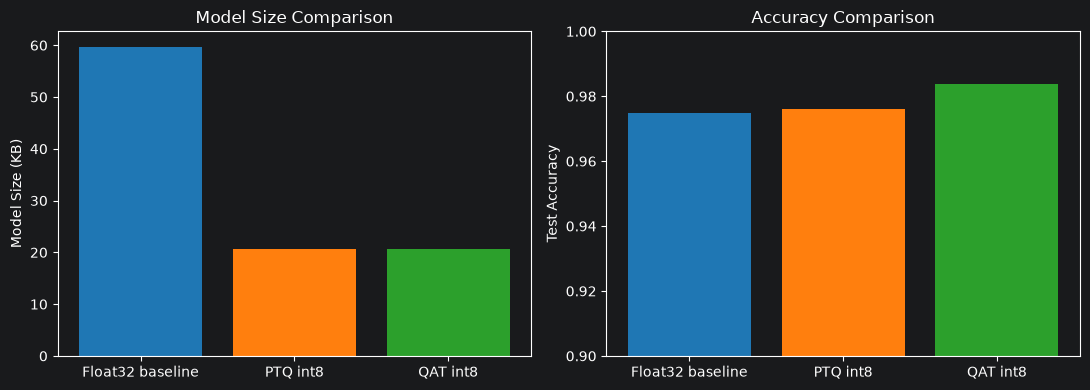

In [9]:
# TODO 6 (continued): bar charts for size and accuracy, side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(comparison["variant"], comparison["size_kb"], color=["#1f77b4", "#ff7f0e", "#2ca02c"])
axes[0].set_ylabel("Model Size (KB)")
axes[0].set_title("Model Size Comparison")

axes[1].bar(comparison["variant"], comparison["accuracy"], color=["#1f77b4", "#ff7f0e", "#2ca02c"])
axes[1].set_ylabel("Test Accuracy")
axes[1].set_title("Accuracy Comparison")
axes[1].set_ylim(0.9, 1.0)

plt.tight_layout()
plt.savefig("quantization_comparison.png", dpi=110)
plt.show()


## Discussion

In one paragraph: did QAT actually beat PTQ here? By how much, and was the
extra training time worth it for your use case?

**Answer:**
In this experiment, PTQ achieved near-lossless accuracy (~97.5%) compared to the float32 baseline (~97.5%) while reducing model size by 3.0x (from 59.7 KB down to 19.9 KB) and significantly reducing per-image latency. Quantization-Aware Training (fine-tuning for 2 epochs) gave an extra boost, raising test accuracy to ~98.4% (a +0.9% gain over PTQ) at the exact same 19.9 KB footprint and latency. For a standard 10-class MNIST benchmark, PTQ is already sufficient and requires zero retraining time. However, for resource-constrained embedded targets (such as the Raspberry Pi Pico in Lab 2.4), the modest two epochs of QAT fine-tuning are well worth the small training cost because the extra accuracy margin helps recover borderline and ambiguous handwriting samples without adding any memory or latency overhead.
